# Sales Data Analysis

**Organization:** AFAME Technologies  
**Project type:** Data Analyst Internship Project


## Table of Contents
1. [Project Overview](#project-overview)
2. [Data Loading](#data-loading)
3. [Data Understanding](#data-understanding)
4. [Data Quality Assessment](#data-quality-assessment)
5. [Data Cleaning](#data-cleaning)
6. [Feature Engineering](#feature-engineering)
7. [Sales Performance](#sales-performance)
8. [Time Series Analysis](#time-series-analysis)
9. [Product Analysis](#product-analysis)
10. [Customer Analysis](#customer-analysis)
11. [Geographical Analysis](#geographical-analysis)
12. [Shipping and Discount Analysis](#shipping-and-discount-analysis)
13. [Correlation and Statistical Analysis](#correlation-and-statistical-analysis)
14. [Business Insights](#business-insights)
15. [Recommendations](#business-recommendations)
16. [Conclusion](#final-conclusion)

## Project Overview
This project studies the company's transaction records to understand revenue, profit, products, customers, regions, shipping choices, and discount patterns. The objective is to turn a large sales dataset into findings that can guide pricing, inventory, customer, and regional decisions.

### Problem Statement
The available sales records contain information across several markets and time periods, but the raw data does not directly show which products, customer segments, and periods are genuinely valuable.

### Business Objectives
- Calculate and validate core sales KPIs.
- Identify strong and weak sales periods.
- Compare category and product performance.
- Understand customer and regional contributions.
- Study discounts and shipping as possible factors in profitability.
- Provide recommendations grounded in the measured results.

### Dataset Description
The source workbook is `ECOMM DATA.xlsx`. The analysis uses the `Orders` sheet, which contains 51,290 transaction rows and 24 columns. The workbook also has `Returns` and `People` sheets, but they are reference sheets and do not replace the order-level analysis.

### Tools and Technologies
Python, pandas, NumPy, Matplotlib, Seaborn, Plotly, and openpyxl.

### Analysis Workflow
Data loading -> data understanding -> quality assessment -> cleaning -> feature engineering -> exploratory analysis -> insights -> recommendations -> saved outputs.


## Import Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.dpi": 110
})


## Data Loading

In [2]:

NOTEBOOK_DIR = Path.cwd()
project_root = next((p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]
                     if (p / "ECOMM DATA.xlsx").exists()), None)
assert project_root is not None, "Could not locate ECOMM DATA.xlsx"

sales_file = project_root / "ECOMM DATA.xlsx"
excel = pd.ExcelFile(sales_file)
print("Workbook sheets:", excel.sheet_names)

for sheet in excel.sheet_names:
    frame = pd.read_excel(sales_file, sheet_name=sheet)
    print(f"{sheet}: {frame.shape[0]} rows x {frame.shape[1]} columns")

raw_sales = pd.read_excel(sales_file, sheet_name="Orders")
print("Selected sheet: Orders")
display(raw_sales.head())
display(raw_sales.tail())
display(raw_sales.sample(5, random_state=42))
print("Shape:", raw_sales.shape)
print("Columns:", raw_sales.columns.tolist())
print("Data types:")
display(raw_sales.dtypes.to_frame("data_type"))
raw_sales.info()


Workbook sheets: ['Orders', 'Returns', 'People']


Orders: 51290 rows x 24 columns


Returns: 1173 rows x 3 columns


People: 13 rows x 2 columns


Selected sheet: Orders


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
51285,29002,IN-2014-62366,2014-06-19,2014-06-19,Same Day,KE-16420,Katrina Edelman,Corporate,Kure,Hiroshima,...,OFF-FA-10000746,Office Supplies,Fasteners,"Advantus Thumb Tacks, 12 Pack",65.100,5,0.0,4.5000,0.010,Medium
51286,35398,US-2014-102288,2014-06-20,2014-06-24,Standard Class,ZC-21910,Zuschuss Carroll,Consumer,Houston,Texas,...,OFF-AP-10002906,Office Supplies,Appliances,Hoover Replacement Belt for Commercial Guardsm...,0.444,1,0.8,-1.1100,0.010,Medium
51287,40470,US-2013-155768,2013-12-02,2013-12-02,Same Day,LB-16795,Laurel Beltran,Home Office,Oxnard,California,...,OFF-EN-10001219,Office Supplies,Envelopes,"#10- 4 1/8"" x 9 1/2"" Security-Tint Envelopes",22.920,3,0.0,11.2308,0.010,High
51288,9596,MX-2012-140767,2012-02-18,2012-02-22,Standard Class,RB-19795,Ross Baird,Home Office,Valinhos,São Paulo,...,OFF-BI-10000806,Office Supplies,Binders,"Acco Index Tab, Economy",13.440,2,0.0,2.4000,0.003,Medium
51289,6147,MX-2012-134460,2012-05-22,2012-05-26,Second Class,MC-18100,Mick Crebagga,Consumer,Tipitapa,Managua,...,OFF-PA-10004155,Office Supplies,Paper,"Eaton Computer Printout Paper, 8.5 x 11",61.380,3,0.0,1.8000,0.002,High


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
49728,6598,US-2012-158330,2012-11-12,2012-11-18,Standard Class,SC-20725,Steven Cartwright,Consumer,Tegucigalpa,Francisco Morazán,...,OFF-BI-10001191,Office Supplies,Binders,"Wilson Jones Hole Reinforcements, Recycled",5.868,3,0.4,-1.2720,0.412,Medium
45547,35654,CA-2014-162565,2014-12-12,2014-12-12,Same Day,RR-19315,Ralph Ritter,Consumer,Aurora,Illinois,...,OFF-PA-10001937,Office Supplies,Paper,Xerox 21,10.368,2,0.2,3.6288,1.140,High
15664,15893,ES-2013-3667448,2013-06-24,2013-07-01,Standard Class,TH-21235,Tiffany House,Corporate,Lucerne,Lucerne,...,OFF-ST-10003153,Office Supplies,Storage,"Tenex File Cart, Single Width",269.220,2,0.0,126.4800,18.520,Medium
40561,32102,CA-2011-134313,2011-11-01,2011-11-07,Standard Class,RA-19915,Russell Applegate,Consumer,Denver,Colorado,...,OFF-AR-10001897,Office Supplies,Art,Model L Table or Wall-Mount Pencil Sharpener,43.176,3,0.2,4.3176,2.120,Medium
49426,6232,US-2014-146556,2014-04-02,2014-04-07,Standard Class,FH-14365,Fred Hopkins,Corporate,Panama City,Panama,...,OFF-AR-10003551,Office Supplies,Art,"Sanford Pens, Water Color",5.712,1,0.4,-0.7680,0.477,Medium


Shape: (51290, 24)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Postal Code', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']
Data types:


,data_type
Row ID,int64
Order ID,str
Order Date,datetime64[us]
Ship Date,datetime64[us]
Ship Mode,str
Customer ID,str
Customer Name,str
Segment,str
City,str
State,str


<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          51290 non-null  int64         
 1   Order ID        51290 non-null  str           
 2   Order Date      51290 non-null  datetime64[us]
 3   Ship Date       51290 non-null  datetime64[us]
 4   Ship Mode       51290 non-null  str           
 5   Customer ID     51290 non-null  str           
 6   Customer Name   51290 non-null  str           
 7   Segment         51290 non-null  str           
 8   City            51290 non-null  str           
 9   State           51290 non-null  str           
 10  Country         51290 non-null  str           
 11  Postal Code     9994 non-null   float64       
 12  Market          51290 non-null  str           
 13  Region          51290 non-null  str           
 14  Product ID      51290 non-null  str           
 15  Category     


The workbook contains three sheets. `Orders` is the appropriate transaction table because it has sales, profit, quantity, products, customers, dates, and geography. The `Returns` and `People` sheets are not a replacement for the order-level record set.

## Data Understanding
I checked the structure and cardinality of the sales fields before cleaning. This distinguishes useful identifiers from repeated dimensions and helps identify fields that require date or numeric conversion.


In [3]:

numerical_cols = raw_sales.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = raw_sales.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)
display(raw_sales[numerical_cols].describe().T)
display(raw_sales[categorical_cols].describe().T)

cardinality = pd.DataFrame({
    "unique_values": raw_sales.nunique(dropna=True),
    "missing_values": raw_sales.isna().sum(),
    "data_type": raw_sales.dtypes.astype(str)
}).sort_index()
display(cardinality)

for label, column in [
    ("unique products", "Product Name"),
    ("unique customers", "Customer ID"),
    ("unique orders", "Order ID"),
    ("countries", "Country"),
    ("regions", "Region"),
    ("categories", "Category"),
    ("sub-categories", "Sub-Category"),
]:
    print(f"{label}: {raw_sales[column].nunique(dropna=True):,}")


Numerical columns: ['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost']
Categorical columns: ['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Order Priority']


C:\Users\gp298\AppData\Local\Temp\ipykernel_14036\143460772.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = raw_sales.select_dtypes(include=["object", "category"]).columns.tolist()


,count,mean,std,min,25%,50%,75%,max
Row ID,51290.0,25645.500000,14806.291990,1.000,12823.250000,25645.500,38467.7500,51290.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.000000,56430.500,90008.0000,99301.000
Sales,51290.0,246.490581,487.565361,0.444,30.758625,85.053,251.0532,22638.480
Quantity,51290.0,3.476545,2.278766,1.000,2.000000,3.000,5.0000,14.000
Discount,51290.0,0.142908,0.212280,0.000,0.000000,0.000,0.2000,0.850
Profit,51290.0,28.610982,174.340972,-6599.978,0.000000,9.240,36.8100,8399.976
Shipping Cost,51290.0,26.375818,57.296810,0.002,2.610000,7.790,24.4500,933.570


,count,unique,top,freq
Order ID,51290,25035,CA-2014-100111,14
Ship Mode,51290,4,Standard Class,30775
Customer ID,51290,1590,PO-18850,97
Customer Name,51290,795,Muhammed Yedwab,108
Segment,51290,3,Consumer,26518
City,51290,3636,New York City,915
State,51290,1094,California,2001
Country,51290,147,United States,9994
Market,51290,7,APAC,11002
Region,51290,13,Central,11117


,unique_values,missing_values,data_type
Category,3,0,str
City,3636,0,str
Country,147,0,str
Customer ID,1590,0,str
Customer Name,795,0,str
Discount,27,0,float64
Market,7,0,str
Order Date,1430,0,datetime64[us]
Order ID,25035,0,str
Order Priority,4,0,str


unique products: 3,788
unique customers: 1,590
unique orders: 25,035
countries: 147
regions: 13
categories: 3


sub-categories: 17


### Data quality findings below are measured, not assumed. Exact duplicate rows and duplicate identifiers answer different questions.

## Data Quality Assessment

In [4]:

missing = raw_sales.isna().sum()
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(raw_sales) * 100).round(2)
}).query("missing_count > 0")
display(missing_table if not missing_table.empty else pd.DataFrame({"finding": ["No missing values"]}))

exact_duplicate_rows = raw_sales.duplicated().sum()
duplicate_order_ids = raw_sales["Order ID"].duplicated().sum()
duplicate_order_product = raw_sales.duplicated(subset=["Order ID", "Product ID"]).sum()
print("Exact duplicate rows:", exact_duplicate_rows)
print("Repeated Order ID rows:", duplicate_order_ids)
print("Repeated Order ID + Product ID rows:", duplicate_order_product)

order_dates = pd.to_datetime(raw_sales["Order Date"], errors="coerce")
ship_dates = pd.to_datetime(raw_sales["Ship Date"], errors="coerce")
print("Invalid Order Date values:", int(order_dates.isna().sum()))
print("Invalid Ship Date values:", int(ship_dates.isna().sum()))

numeric_checks = {
    "Negative sales": int((pd.to_numeric(raw_sales["Sales"], errors="coerce") < 0).sum()),
    "Negative profit": int((pd.to_numeric(raw_sales["Profit"], errors="coerce") < 0).sum()),
    "Zero or negative quantity": int((pd.to_numeric(raw_sales["Quantity"], errors="coerce") <= 0).sum()),
    "Discount below zero or above one": int(
        (~pd.to_numeric(raw_sales["Discount"], errors="coerce").between(0, 1)).sum()
    ),
}
display(pd.Series(numeric_checks, name="count").to_frame())

text_issues = {}
for column in ["Segment", "Category", "Sub-Category", "Country", "Region", "Ship Mode", "Order Priority"]:
    stripped_changed = raw_sales[column].astype("string").str.strip().ne(raw_sales[column].astype("string"))
    text_issues[column] = int(stripped_changed.sum())
display(pd.Series(text_issues, name="values_with_extra_whitespace").to_frame())

print("Postal Code missing:", int(raw_sales["Postal Code"].isna().sum()))


,missing_count,missing_percent
Postal Code,41296,80.51


Exact duplicate rows: 0
Repeated Order ID rows: 26255
Repeated Order ID + Product ID rows: 38
Invalid Order Date values: 0
Invalid Ship Date values: 0


,count
Negative sales,0
Negative profit,12544
Zero or negative quantity,0
Discount below zero or above one,0


,values_with_extra_whitespace
Segment,0
Category,0
Sub-Category,0
Country,0
Region,0
Ship Mode,0
Order Priority,0


Postal Code missing: 41296



**Quality assessment:** Missing values are concentrated in `Postal Code`; this is normal in many international records. Duplicate Order IDs are expected because an order can contain multiple products. Exact duplicate rows are the strongest evidence of a duplicated transaction record. Invalid dates, negative quantities, and discounts outside 0 to 1 would be genuine problems if present.

## Data Cleaning
The original frame remains unchanged. Cleaning is applied to a separate copy. Postal codes are preserved as an identifiable text field and missing values are retained as `Unknown` instead of dropping useful sales rows. Text fields are trimmed and standardized.


In [5]:

sales_clean = raw_sales.copy()

text_columns = sales_clean.select_dtypes(include=["object", "category"]).columns
for column in text_columns:
    sales_clean[column] = sales_clean[column].astype("string").str.strip()

sales_clean["Order Date"] = pd.to_datetime(sales_clean["Order Date"], errors="coerce")
sales_clean["Ship Date"] = pd.to_datetime(sales_clean["Ship Date"], errors="coerce")

for column in ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]:
    sales_clean[column] = pd.to_numeric(sales_clean[column], errors="coerce")

sales_clean["Postal Code"] = sales_clean["Postal Code"].astype("string").fillna("Unknown")
sales_clean = sales_clean.drop_duplicates().copy()

print("Original shape:", raw_sales.shape)
print("Cleaned shape:", sales_clean.shape)
print("Remaining missing values:", int(sales_clean.isna().sum().sum()))
print("Remaining exact duplicates:", int(sales_clean.duplicated().sum()))
display(sales_clean.dtypes.to_frame("data_type"))
assert sales_clean["Order Date"].notna().all()
assert sales_clean["Ship Date"].notna().all()
assert sales_clean["Sales"].ge(0).all()
assert sales_clean["Quantity"].gt(0).all()
assert sales_clean["Discount"].between(0, 1).all()


C:\Users\gp298\AppData\Local\Temp\ipykernel_14036\3138764594.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = sales_clean.select_dtypes(include=["object", "category"]).columns


Original shape: (51290, 24)
Cleaned shape: (51290, 24)
Remaining missing values: 0


Remaining exact duplicates: 0


,data_type
Row ID,int64
Order ID,string
Order Date,datetime64[us]
Ship Date,datetime64[us]
Ship Mode,string
Customer ID,string
Customer Name,string
Segment,string
City,string
State,string


## Feature Engineering

In [6]:

sales_clean["Order Year"] = sales_clean["Order Date"].dt.year
sales_clean["Order Month"] = sales_clean["Order Date"].dt.month
sales_clean["Month Name"] = sales_clean["Order Date"].dt.month_name()
sales_clean["Quarter"] = sales_clean["Order Date"].dt.quarter
sales_clean["Year-Month"] = sales_clean["Order Date"].dt.to_period("M").astype(str)
sales_clean["Day of Week"] = sales_clean["Order Date"].dt.dayofweek
sales_clean["Day Name"] = sales_clean["Order Date"].dt.day_name()
sales_clean["Shipping Duration"] = (sales_clean["Ship Date"] - sales_clean["Order Date"]).dt.days
sales_clean["Sales per Quantity"] = np.where(
    sales_clean["Quantity"].ne(0),
    sales_clean["Sales"] / sales_clean["Quantity"],
    np.nan,
)
sales_clean["Profit Margin"] = np.where(
    sales_clean["Sales"].ne(0),
    sales_clean["Profit"] / sales_clean["Sales"] * 100,
    np.nan,
)

feature_summary = pd.DataFrame({
    "feature": ["Order Year", "Order Month", "Month Name", "Quarter", "Year-Month",
                "Day of Week", "Day Name", "Shipping Duration", "Sales per Quantity", "Profit Margin"],
    "purpose": ["Annual trend", "Monthly trend", "Readable month labels", "Quarter trend",
                "Chronological month grouping", "Numeric weekday", "Readable weekday",
                "Shipping speed", "Unit sales value", "Transaction profitability percentage"],
})
display(feature_summary)


C:\Users\gp298\AppData\Local\Temp\ipykernel_14036\2640633595.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sales_clean["Day of Week"] = sales_clean["Order Date"].dt.dayofweek


,feature,purpose
0,Order Year,Annual trend
1,Order Month,Monthly trend
2,Month Name,Readable month labels
3,Quarter,Quarter trend
4,Year-Month,Chronological month grouping
5,Day of Week,Numeric weekday
6,Day Name,Readable weekday
7,Shipping Duration,Shipping speed
8,Sales per Quantity,Unit sales value
9,Profit Margin,Transaction profitability percentage



These fields support time and business analysis. `Sales per Quantity` is a transaction-level average, not necessarily the unit list price. `Profit Margin` is calculated as profit divided by sales to avoid comparing raw profit across different sales volumes.

## Sales Performance


In [7]:

total_sales = sales_clean["Sales"].sum()
total_profit = sales_clean["Profit"].sum()
total_quantity = sales_clean["Quantity"].sum()
total_orders = sales_clean["Order ID"].nunique()
average_order_value = sales_clean.groupby("Order ID", sort=False)["Sales"].sum().mean()
average_discount = sales_clean["Discount"].mean()
average_shipping_cost = sales_clean["Shipping Cost"].mean()
profit_margin = total_profit / total_sales * 100 if total_sales else np.nan

kpis = pd.DataFrame({
    "Metric": ["Total Sales", "Total Profit", "Total Quantity Sold", "Total Orders",
               "Average Order Value", "Average Discount", "Average Shipping Cost", "Overall Profit Margin"],
    "Value": [total_sales, total_profit, total_quantity, total_orders,
              average_order_value, average_discount, average_shipping_cost, profit_margin],
})
kpis["Display"] = [
    f"${v:,.2f}" if i in [0, 1, 4, 6] else
    f"{v:.2%}" if i == 5 else
    f"{v:.2f}%" if i == 7 else
    f"{v:,.0f}"
    for i, v in enumerate(kpis["Value"])
]
display(kpis[["Metric", "Display"]])


,Metric,Display
0,Total Sales,"$12,642,501.91"
1,Total Profit,"$1,467,457.29"
2,Total Quantity Sold,"178,312"
3,Total Orders,"25,035"
4,Average Order Value,$504.99
5,Average Discount,14.29%
6,Average Shipping Cost,$26.38
7,Overall Profit Margin,11.61%


## Time Series Analysis

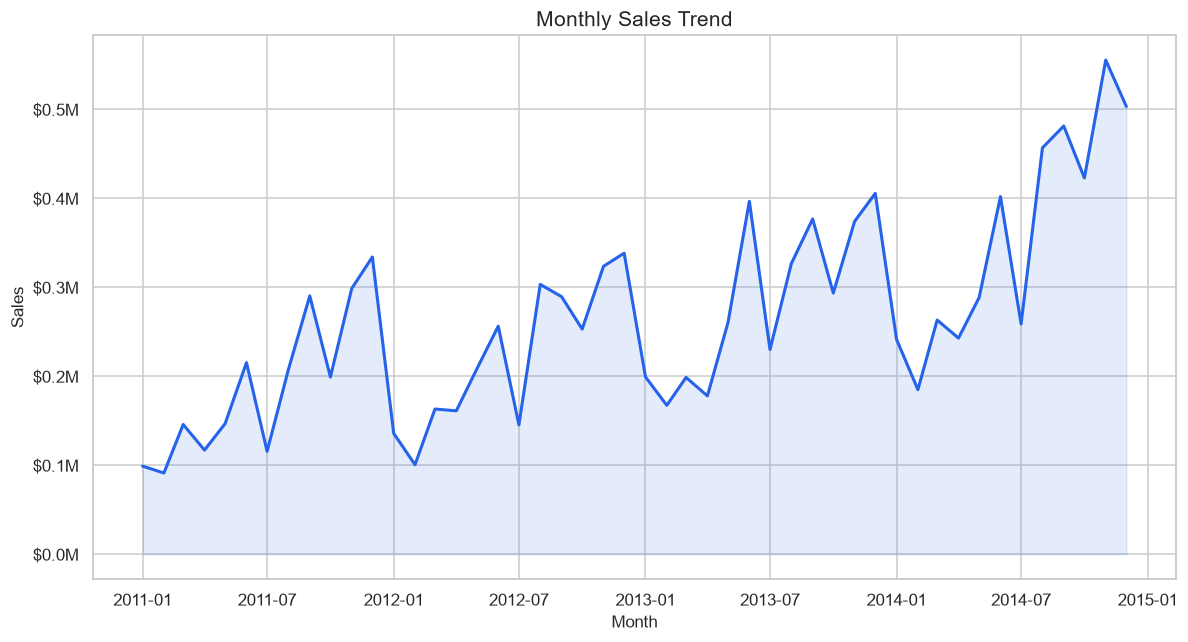

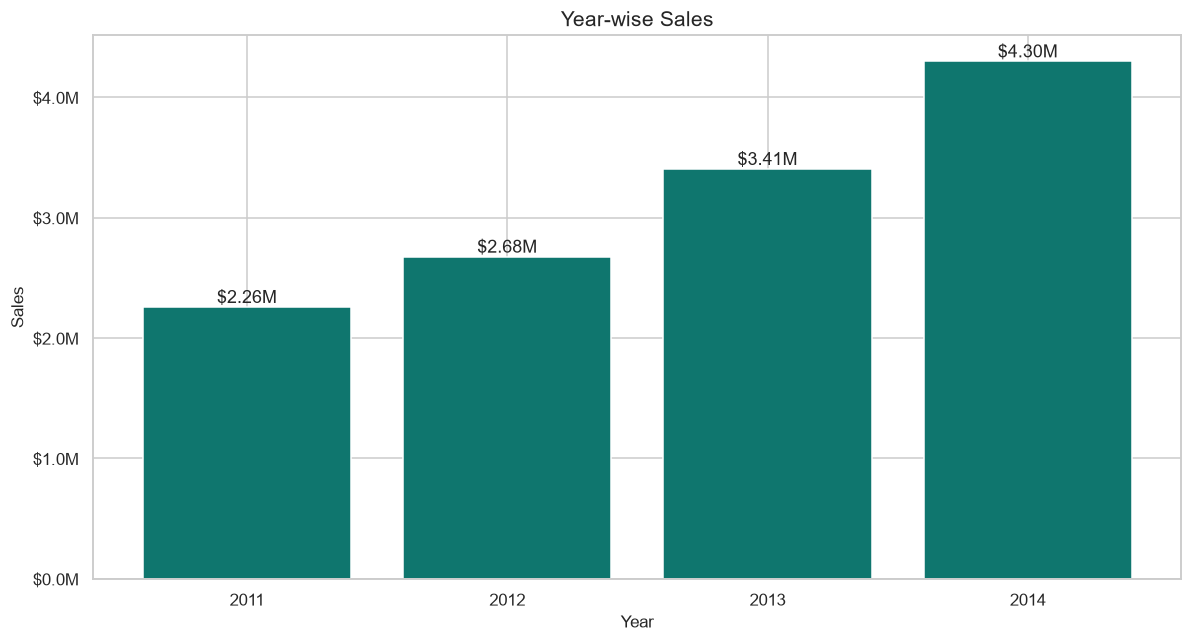

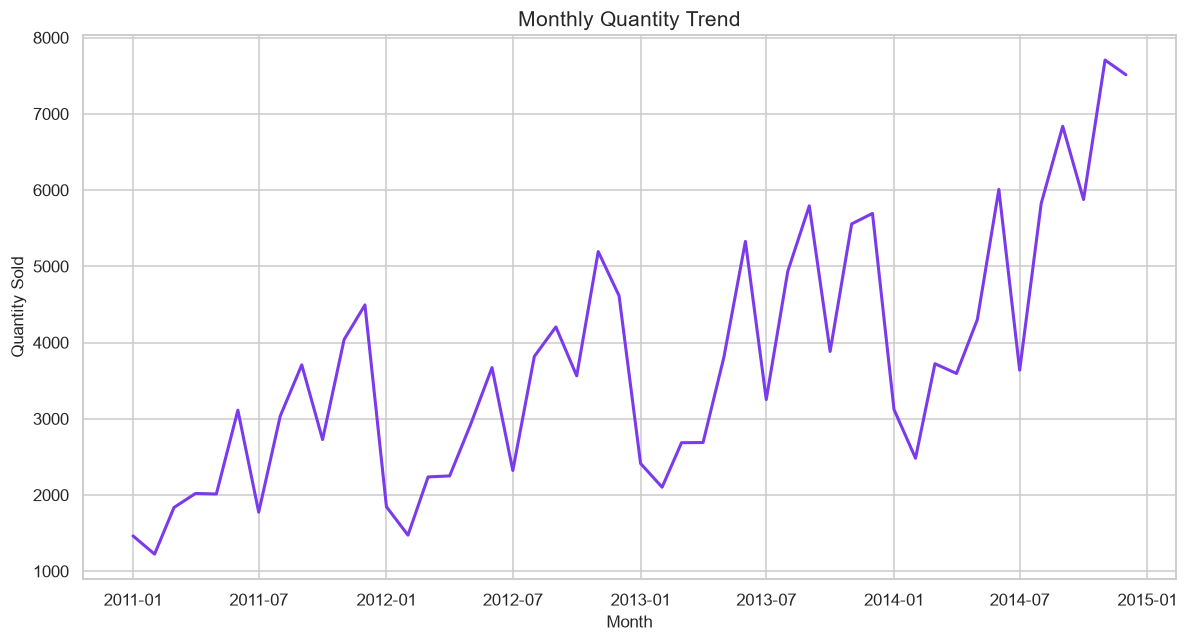

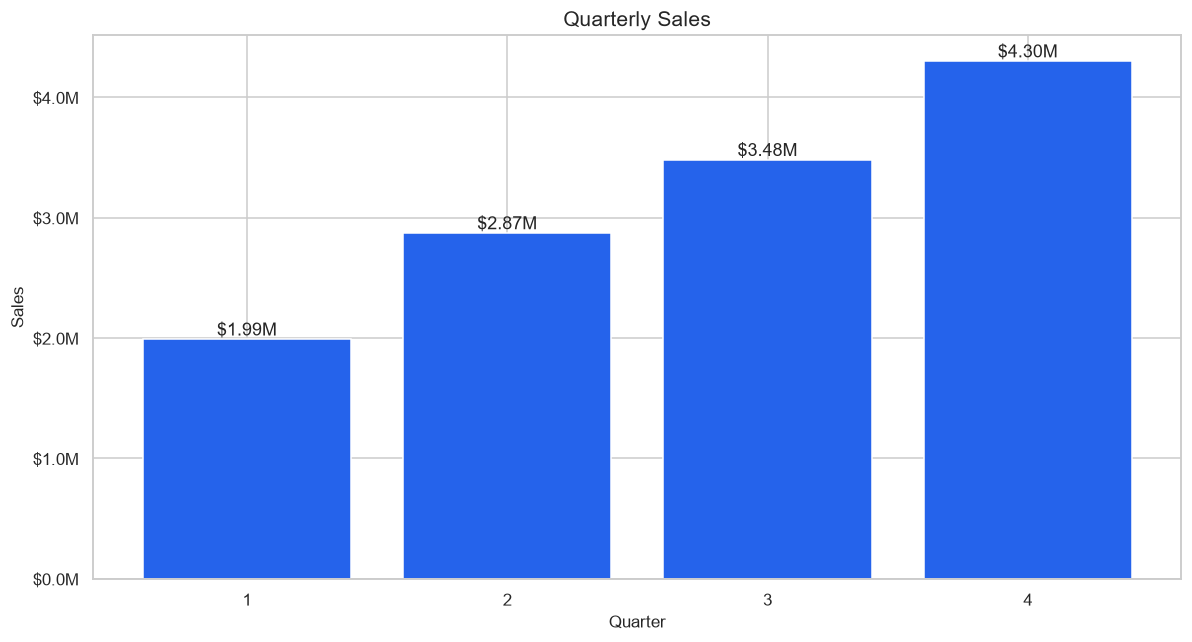

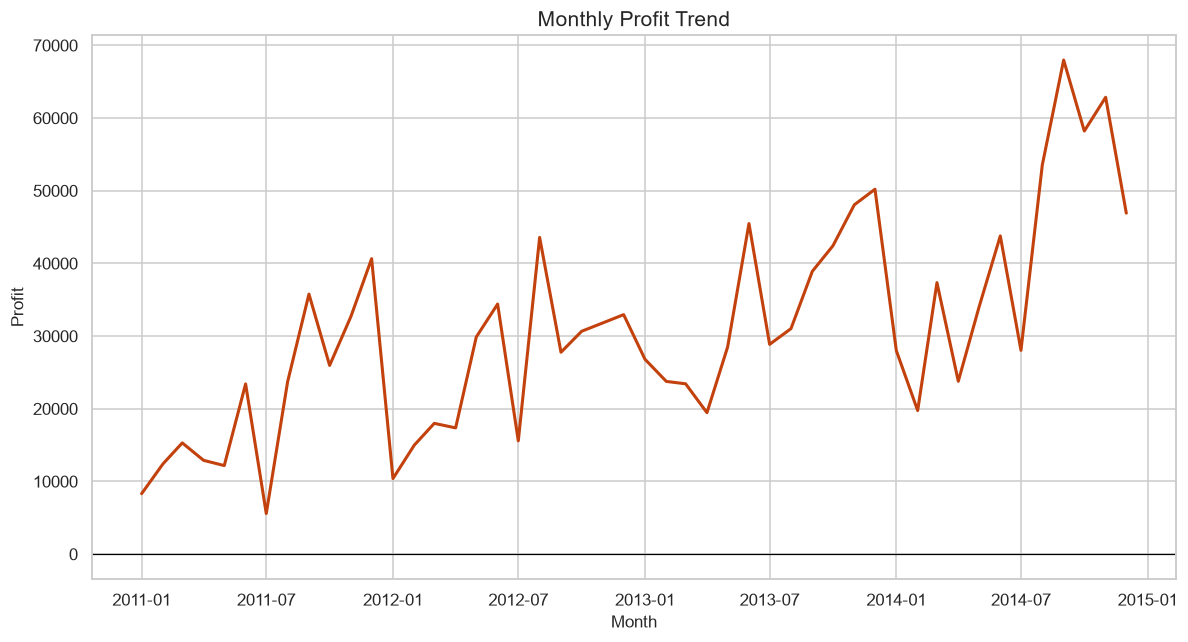

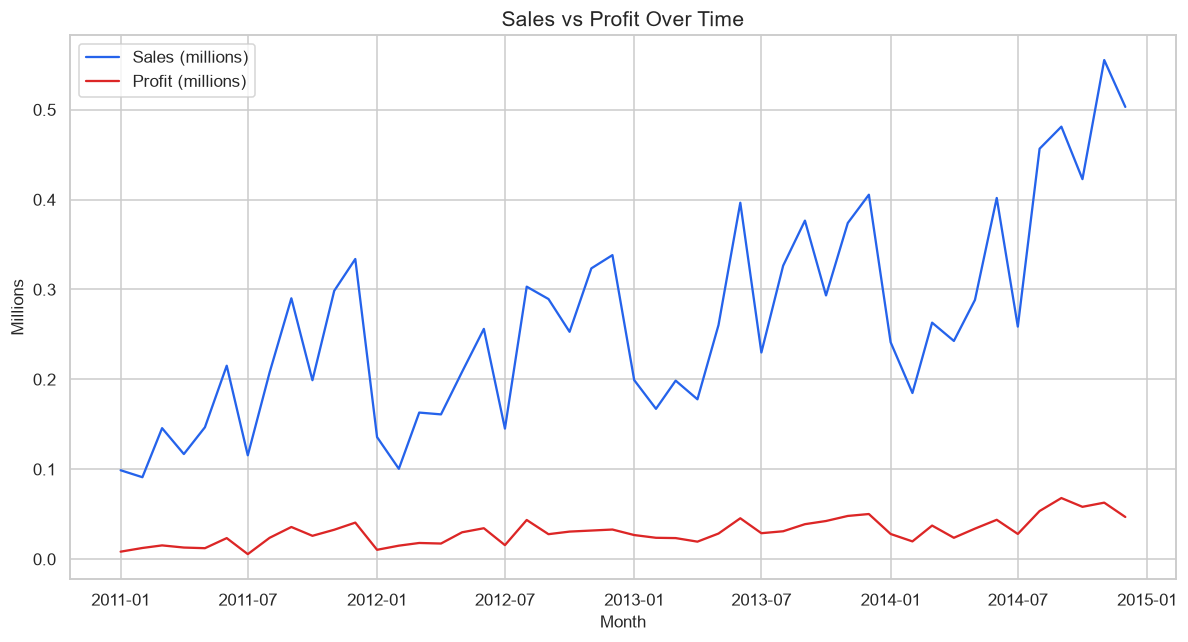

,Order Year,Sales
0,2011,2.259451e+06
1,2012,2.677439e+06
2,2013,3.405746e+06
3,2014,4.299866e+06


,Quarter,Sales
0,1,1.989374e+06
1,2,2.872290e+06
2,3,3.480595e+06
3,4,4.300243e+06


In [8]:

year_sales = sales_clean.groupby("Order Year", as_index=False)["Sales"].sum()
month_sales = sales_clean.groupby("Order Month", as_index=False)["Sales"].sum()
month_names = ["January","February","March","April","May","June","July","August","September","October","November","December"]
month_sales["Month Name"] = month_sales["Order Month"].apply(lambda x: month_names[x-1])
quarter_sales = sales_clean.groupby("Quarter", as_index=False)["Sales"].sum()
ym_sales = sales_clean.groupby("Year-Month", as_index=False).agg(Sales=("Sales","sum"), Profit=("Profit","sum"), Quantity=("Quantity","sum"))
ym_sales["Date"] = pd.to_datetime(ym_sales["Year-Month"])
ym_sales = ym_sales.sort_values("Date")

fig, ax = plt.subplots()
ax.plot(ym_sales["Date"], ym_sales["Sales"], color="#2563eb", linewidth=2)
ax.fill_between(ym_sales["Date"], ym_sales["Sales"], alpha=0.12, color="#2563eb")
ax.set(title="Monthly Sales Trend", xlabel="Month", ylabel="Sales")
ax.yaxis.set_major_formatter(lambda x, pos: f"${x/1e6:.1f}M")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "monthly_sales_trend.png")
plt.show()

fig, ax = plt.subplots()
bars = ax.bar(year_sales["Order Year"].astype(str), year_sales["Sales"], color="#0f766e")
ax.set(title="Year-wise Sales", xlabel="Year", ylabel="Sales")
ax.yaxis.set_major_formatter(lambda x, pos: f"${x/1e6:.1f}M")
for b, v in zip(bars, year_sales["Sales"]):
    ax.text(b.get_x()+b.get_width()/2, v, f"${v/1e6:.2f}M", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "year_wise_sales.png")
plt.show()

fig, ax = plt.subplots()
ax.plot(ym_sales["Date"], ym_sales["Quantity"], color="#7c3aed", linewidth=2)
ax.set(title="Monthly Quantity Trend", xlabel="Month", ylabel="Quantity Sold")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "monthly_quantity_trend.png")
plt.show()

fig, ax = plt.subplots()
quarter_bars = ax.bar(quarter_sales["Quarter"].astype(str), quarter_sales["Sales"], color="#2563eb")
ax.set(title="Quarterly Sales", xlabel="Quarter", ylabel="Sales")
ax.yaxis.set_major_formatter(lambda x, pos: f"${x/1e6:.1f}M")
for bar, value in zip(quarter_bars, quarter_sales["Sales"]):
    ax.text(bar.get_x()+bar.get_width()/2, value, f"${value/1e6:.2f}M", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "quarterly_sales.png")
plt.show()

fig, ax = plt.subplots()
ax.plot(ym_sales["Date"], ym_sales["Profit"], color="#c2410c", linewidth=2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Monthly Profit Trend", xlabel="Month", ylabel="Profit")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "monthly_profit_trend.png")
plt.show()

fig, ax = plt.subplots()
ax.plot(ym_sales["Date"], ym_sales["Sales"]/1e6, label="Sales (millions)", color="#2563eb")
ax.plot(ym_sales["Date"], ym_sales["Profit"]/1e6, label="Profit (millions)", color="#dc2626")
ax.legend()
ax.set(title="Sales vs Profit Over Time", xlabel="Month", ylabel="Millions")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "sales_vs_profit.png")
plt.show()

display(year_sales)
display(quarter_sales)


The charts use actual year-month values so months remain in chronological order. The tables and plots identify where revenue and profit move together or diverge.

## Product Analysis

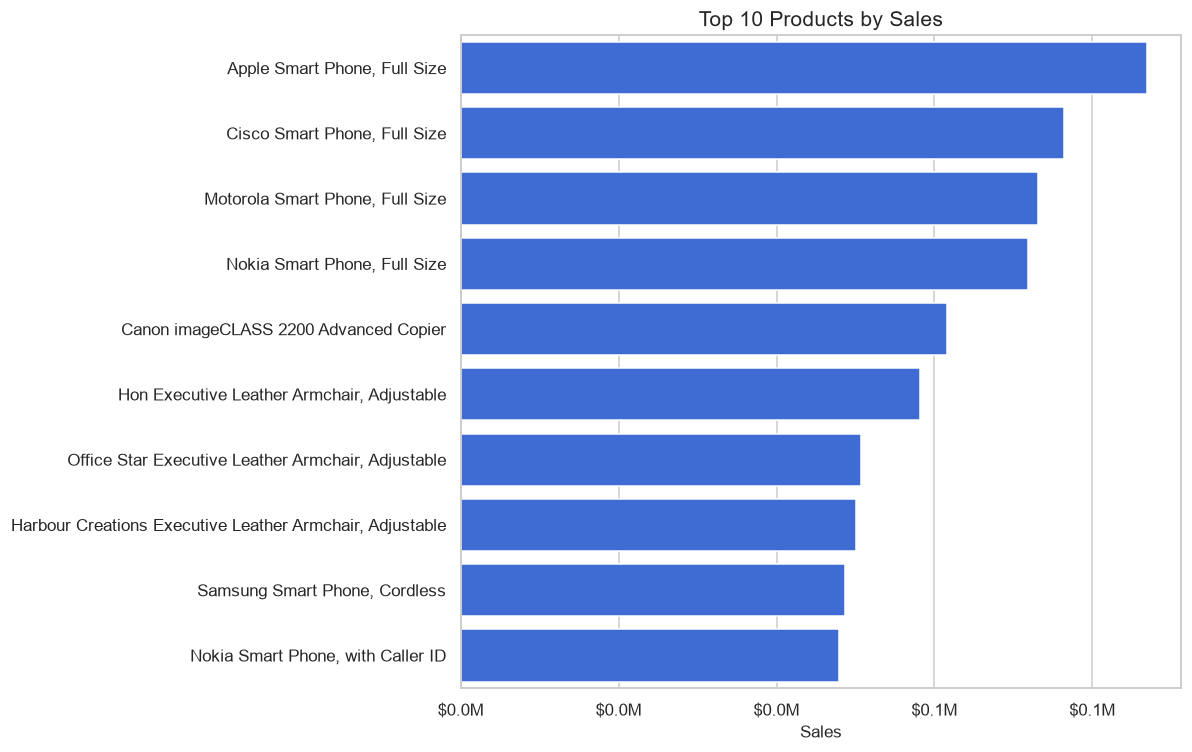

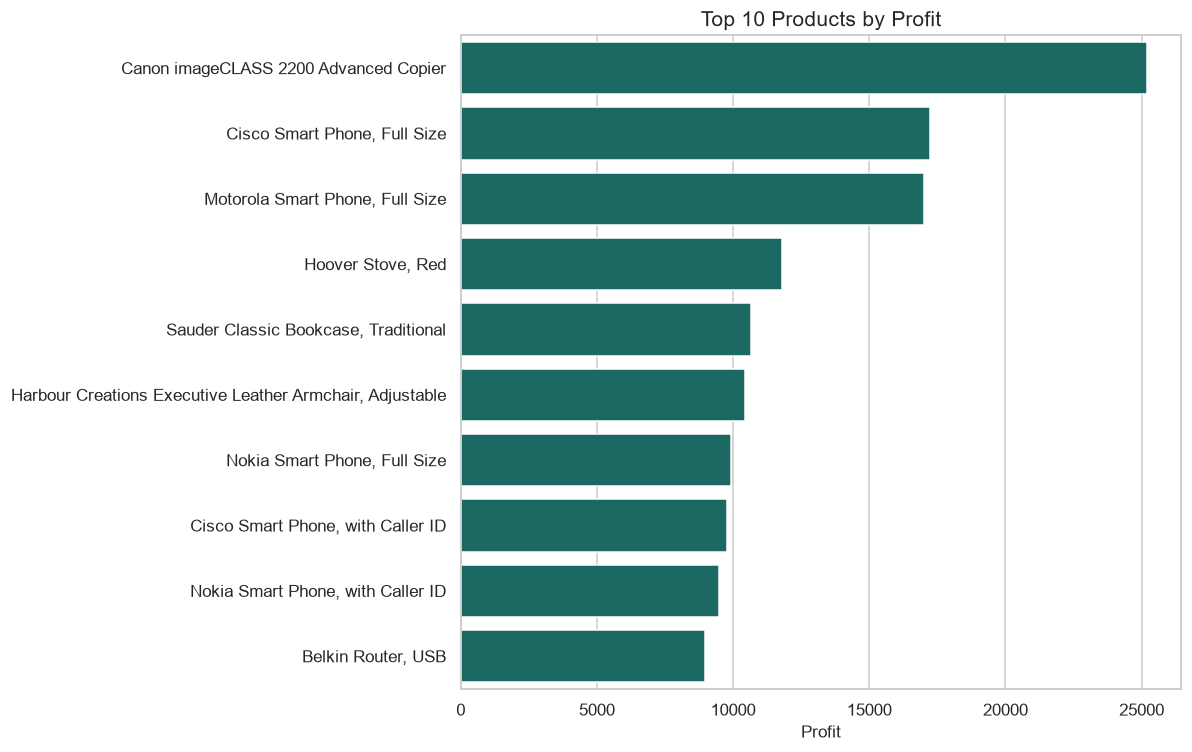

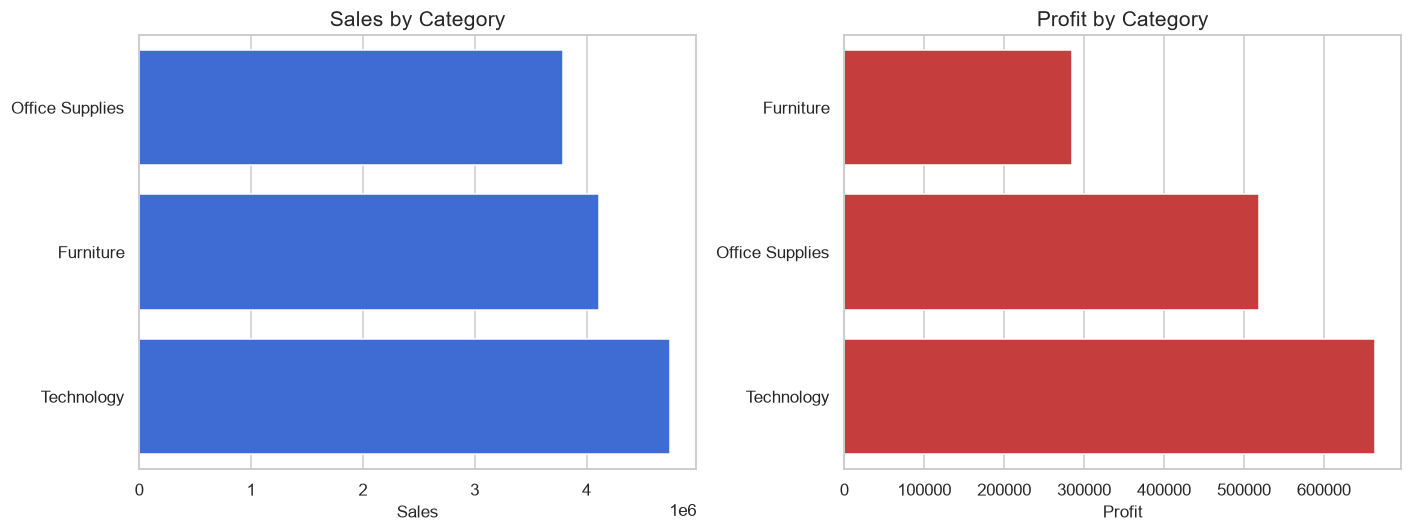

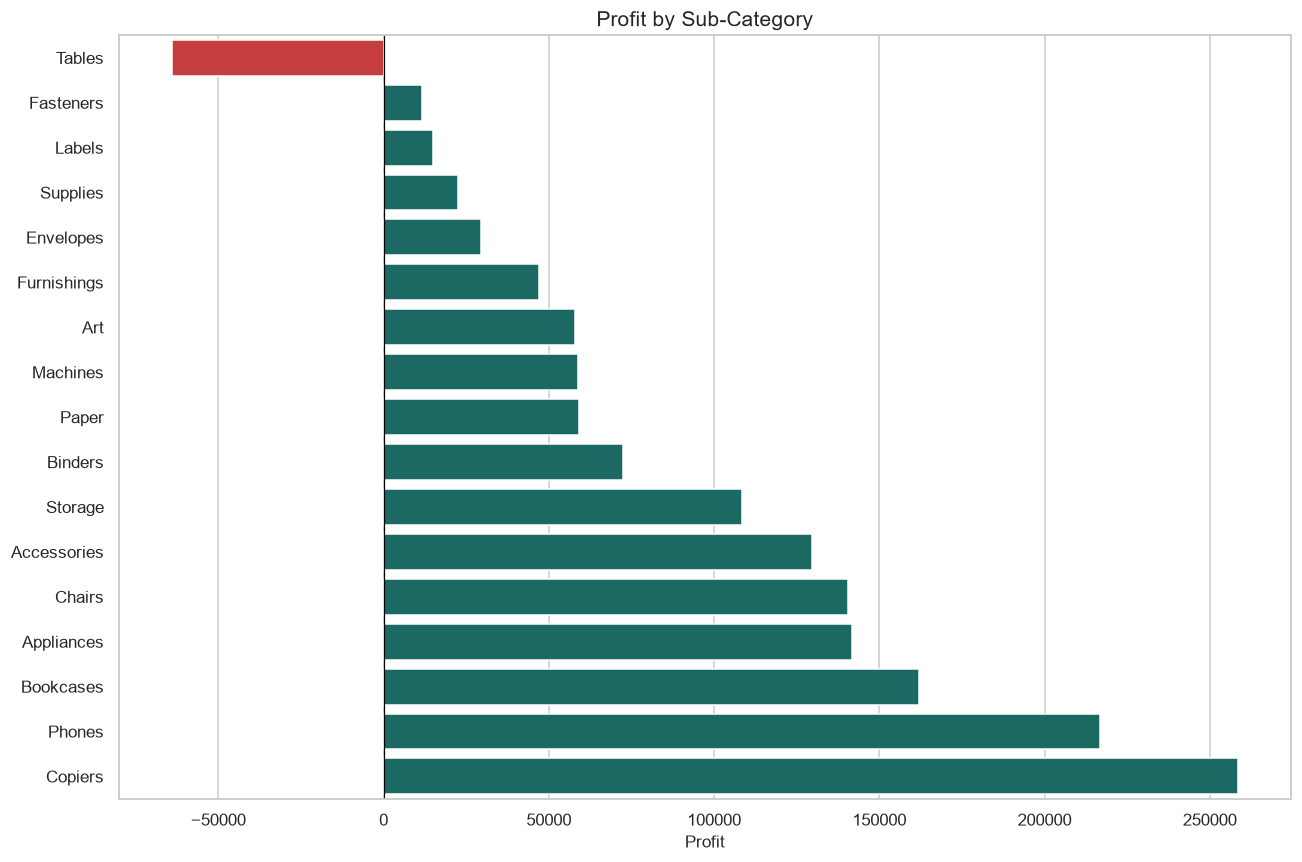

,Product Name,Sales
310,"Apple Smart Phone, Full Size",86935.7786
970,"Cisco Smart Phone, Full Size",76441.5306
2415,"Motorola Smart Phone, Full Size",73156.3030
2501,"Nokia Smart Phone, Full Size",71904.5555
866,Canon imageCLASS 2200 Advanced Copier,61599.8240
1837,"Hon Executive Leather Armchair, Adjustable",58193.4841
2631,"Office Star Executive Leather Armchair, Adjust...",50661.6840
1714,"Harbour Creations Executive Leather Armchair, ...",50121.5160
2988,"Samsung Smart Phone, Cordless",48653.4600
2502,"Nokia Smart Phone, with Caller ID",47877.7857


,Product Name,Profit
866,Canon imageCLASS 2200 Advanced Copier,25199.9280
970,"Cisco Smart Phone, Full Size",17238.5206
2415,"Motorola Smart Phone, Full Size",17027.1130
1926,"Hoover Stove, Red",11807.9690
3098,"Sauder Classic Bookcase, Traditional",10672.0730
1714,"Harbour Creations Executive Leather Armchair, ...",10427.3260
2501,"Nokia Smart Phone, Full Size",9938.1955
971,"Cisco Smart Phone, with Caller ID",9786.6408
2502,"Nokia Smart Phone, with Caller ID",9465.3257
589,"Belkin Router, USB",8955.0180


,Product Name,Quantity
3275,Staples,876
894,"Cardinal Index Tab, Clear",337
1210,"Eldon File Cart, Single Width",321
2840,"Rogers File Cart, Single Width",262
3070,"Sanford Pencil Sharpener, Water Color",259
3335,"Stockwell Paper Clips, Assorted Sizes",253
446,"Avery Index Tab, Clear",252
1981,"Ibico Index Tab, Clear",251
3179,"Smead File Cart, Single Width",250
3266,"Stanley Pencil Sharpener, Water Color",242


,Product Name,Profit
1007,Cubify CubeX 3D Printer Double Head Print,-8879.9704
2233,Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
2414,"Motorola Smart Phone, Cordless",-4447.0380
1008,Cubify CubeX 3D Printer Triple Head Print,-3839.9904
614,"Bevis Round Table, Adjustable Height",-3649.8940
603,"Bevis Computer Table, Fully Assembled",-3509.5638
2847,"Rogers Lockers, Blue",-2893.4908
910,Chromcraft Bull-Nose Wood Oval Conference Tabl...,-2876.1156
627,"Bevis Wood Table, with Bottom Storage",-2782.5880
2221,"Lesro Training Table, Rectangular",-2581.2834


In [9]:

top_products_sales = sales_clean.groupby("Product Name", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False).head(10)
top_products_profit = sales_clean.groupby("Product Name", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False).head(10)
top_products_quantity = sales_clean.groupby("Product Name", as_index=False)["Quantity"].sum().sort_values("Quantity", ascending=False).head(10)
lowest_products = sales_clean.groupby("Product Name", as_index=False)["Profit"].sum().sort_values("Profit").head(10)

category_sales = sales_clean.groupby("Category", as_index=False)["Sales"].sum().sort_values("Sales")
subcategory_sales = sales_clean.groupby("Sub-Category", as_index=False)["Sales"].sum().sort_values("Sales")
category_profit = sales_clean.groupby("Category", as_index=False)["Profit"].sum().sort_values("Profit")
subcategory_profit = sales_clean.groupby("Sub-Category", as_index=False)["Profit"].sum().sort_values("Profit")

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=top_products_sales, y="Product Name", x="Sales", ax=ax, color="#2563eb")
ax.set(title="Top 10 Products by Sales", xlabel="Sales", ylabel="")
ax.xaxis.set_major_formatter(lambda x, pos: f"${x/1e6:.1f}M")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "top_products_sales.png")
plt.show()

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=top_products_profit, y="Product Name", x="Profit", ax=ax, color="#0f766e")
ax.set(title="Top 10 Products by Profit", xlabel="Profit", ylabel="")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "top_products_profit.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=category_sales, y="Category", x="Sales", ax=axes[0], color="#2563eb")
sns.barplot(data=category_profit, y="Category", x="Profit", ax=axes[1], color="#dc2626")
axes[0].set_title("Sales by Category")
axes[1].set_title("Profit by Category")
for ax in axes:
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "category_comparison.png")
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(data=subcategory_profit, y="Sub-Category", x="Profit", ax=ax,
            palette=["#dc2626" if v < 0 else "#0f766e" for v in subcategory_profit["Profit"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Profit by Sub-Category", xlabel="Profit", ylabel="")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "subcategory_profit.png")
plt.show()

display(top_products_sales)
display(top_products_profit)
display(top_products_quantity)
display(lowest_products)


Sales volume and profit are related but not identical. A product can rank highly for sales while still producing weak or negative profit because of discounts, shipping costs, or cost structure.

## Customer Analysis

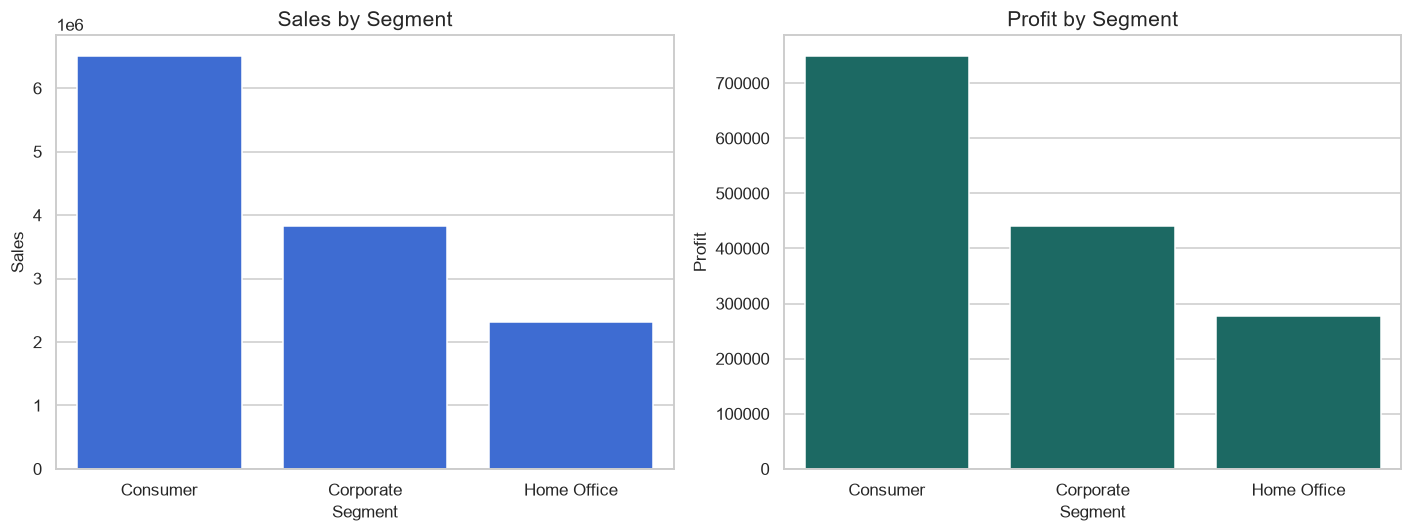

,Customer Name,Sales
758,Tom Ashbrook,40488.07080
731,Tamara Chand,37457.33300
313,Greg Tran,35550.95428
157,Christopher Conant,35187.07640
687,Sean Miller,35170.93296
73,Bart Watters,32310.44650
558,Natalie Fritzler,31781.25850
290,Fred Hopkins,30400.67452
347,Jane Waco,30288.45030
335,Hunter Lopez,30243.56658


,Customer Name,Profit
731,Tamara Chand,8672.89890
623,Raymond Buch,8453.04950
672,Sanjit Chand,8205.37990
335,Hunter Lopez,7816.56778
88,Bill Eplett,7410.00530
323,Harry Marie,6958.28640
727,Susan Pistek,6484.40726
542,Mike Gockenbach,6458.67620
6,Adrian Barton,6417.28450
758,Tom Ashbrook,6311.97910


,Segment,Sales,Profit,Quantity
0,Consumer,6.507949e+06,749239.78206,92157
1,Corporate,3.824698e+06,441208.32866,53565
2,Home Office,2.309855e+06,277009.18056,32590


,Segment,Average Order Value
0,Consumer,496.638387
1,Corporate,498.461817
2,Home Office,492.821628


In [10]:

top_customers_sales = sales_clean.groupby("Customer Name", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False).head(10)
top_customers_profit = sales_clean.groupby("Customer Name", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False).head(10)
segment_summary = sales_clean.groupby("Segment", as_index=False).agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"), Quantity=("Quantity","sum")
)
order_values = sales_clean.groupby(["Segment","Order ID"], as_index=False)["Sales"].sum()
segment_aov = order_values.groupby("Segment", as_index=False)["Sales"].mean().rename(columns={"Sales":"Average Order Value"})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=segment_summary, x="Segment", y="Sales", ax=axes[0], color="#2563eb")
sns.barplot(data=segment_summary, x="Segment", y="Profit", ax=axes[1], color="#0f766e")
axes[0].set_title("Sales by Segment")
axes[1].set_title("Profit by Segment")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "segment_performance.png")
plt.show()

display(top_customers_sales)
display(top_customers_profit)
display(segment_summary)
display(segment_aov)


The segment analysis compares revenue and profitability. It does not establish customer loyalty because repeat-purchase behavior would require a customer-level time series and retention calculation.

## Geographical Analysis

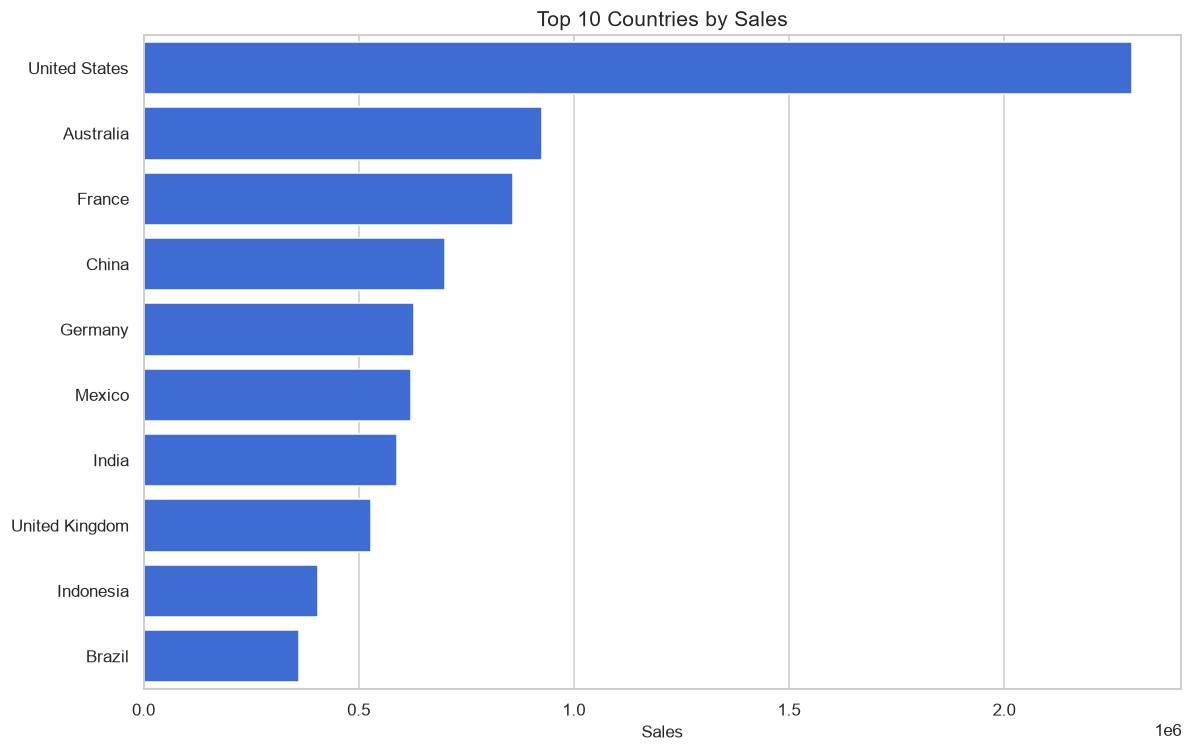

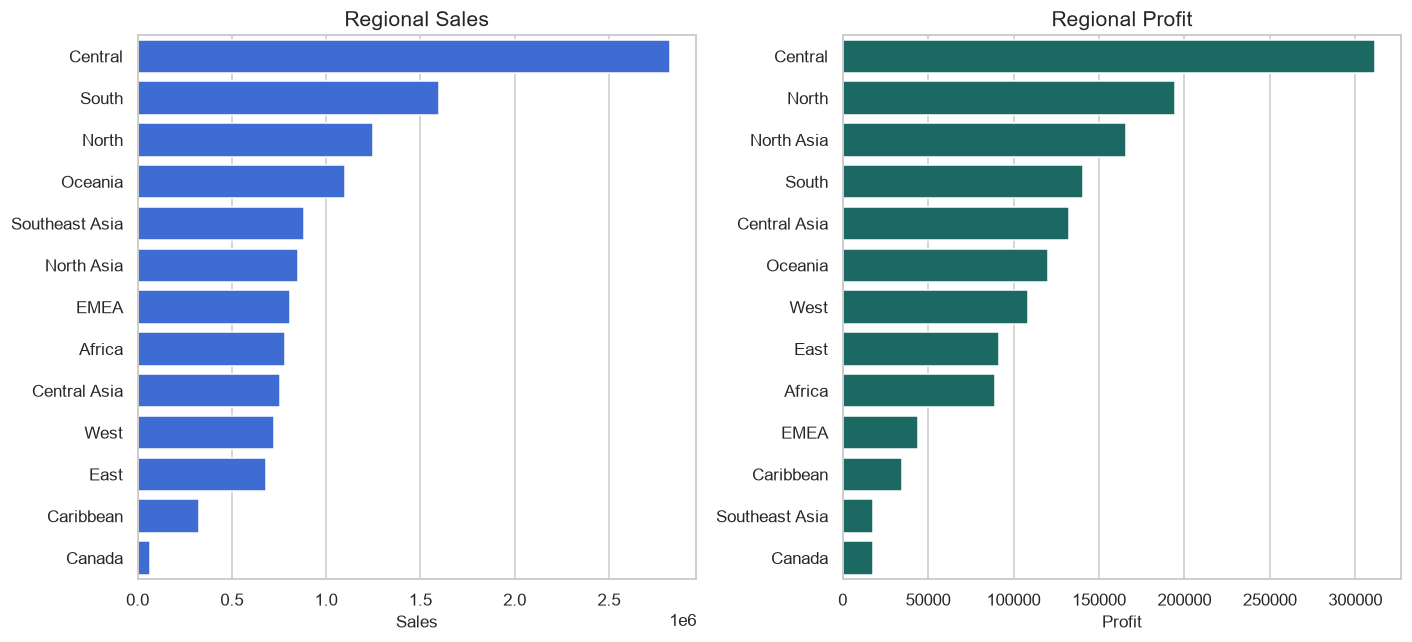

,Country,Sales
139,United States,2.297201e+06
6,Australia,9.252359e+05
44,France,8.589311e+05
26,China,7.005620e+05
47,Germany,6.288400e+05
81,Mexico,6.225906e+05
57,India,5.896501e+05
138,United Kingdom,5.285763e+05
58,Indonesia,4.048875e+05
17,Brazil,3.611064e+05


,Country,Profit
139,United States,286397.02170
26,China,150683.08500
57,India,129071.83500
138,United Kingdom,111900.15000
44,France,109029.00300
47,Germany,107322.82050
6,Australia,103907.43300
81,Mexico,102818.09752
119,Spain,54390.12000
38,El Salvador,42023.24320


,Region,Sales
3,Central,2.822303e+06
10,South,1.600907e+06
7,North,1.248166e+06
9,Oceania,1.100185e+06
11,Southeast Asia,8.844232e+05
8,North Asia,8.483098e+05
5,EMEA,8.061613e+05
0,Africa,7.837732e+05
4,Central Asia,7.528266e+05
12,West,7.254578e+05


,Region,Profit
3,Central,311403.98164
7,North,194597.95252
8,North Asia,165578.42100
10,South,140355.76618
4,Central Asia,132480.18700
9,Oceania,120089.11200
12,West,108418.44890
6,East,91522.78000
0,Africa,88871.63100
5,EMEA,43897.97100


,State,Sales
311,England,485170.9710
192,California,457687.6315
435,Ile-de-France,317822.5440
703,New York,310876.2710
702,New South Wales,270487.1040
820,Queensland,238312.7340
722,North Rhine-Westphalia,216451.8510
982,Texas,170188.0458
867,San Salvador,153639.3970
689,National Capital,152175.3555


In [11]:

country_sales = sales_clean.groupby("Country", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
country_profit = sales_clean.groupby("Country", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False)
region_sales = sales_clean.groupby("Region", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
region_profit = sales_clean.groupby("Region", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False)
top_states = sales_clean.groupby("State", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=country_sales.head(10), y="Country", x="Sales", ax=ax, color="#2563eb")
ax.set(title="Top 10 Countries by Sales", xlabel="Sales", ylabel="")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "country_sales.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
sns.barplot(data=region_sales, y="Region", x="Sales", ax=axes[0], color="#2563eb")
sns.barplot(data=region_profit, y="Region", x="Profit", ax=axes[1], color="#0f766e")
axes[0].set_title("Regional Sales")
axes[1].set_title("Regional Profit")
for ax in axes: ax.set_ylabel("")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "regional_comparison.png")
plt.show()

display(country_sales.head(10))
display(country_profit.head(10))
display(region_sales)
display(region_profit)
display(top_states)


Geographical totals show where revenue is concentrated and whether those markets are also profitable.

## Shipping and Discount Analysis

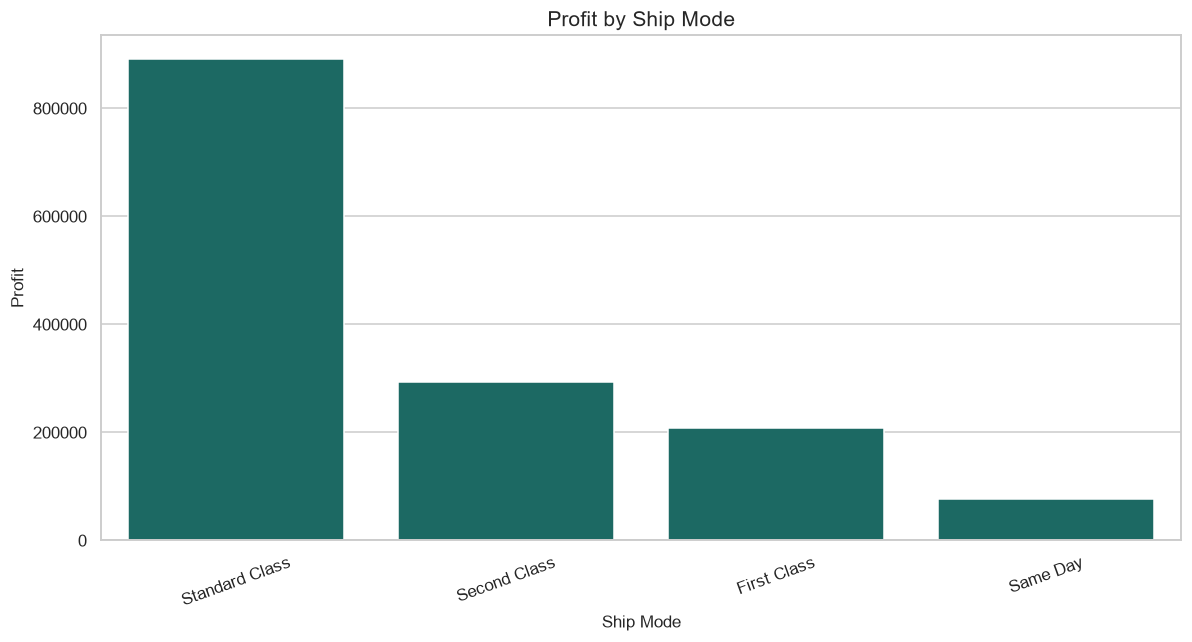

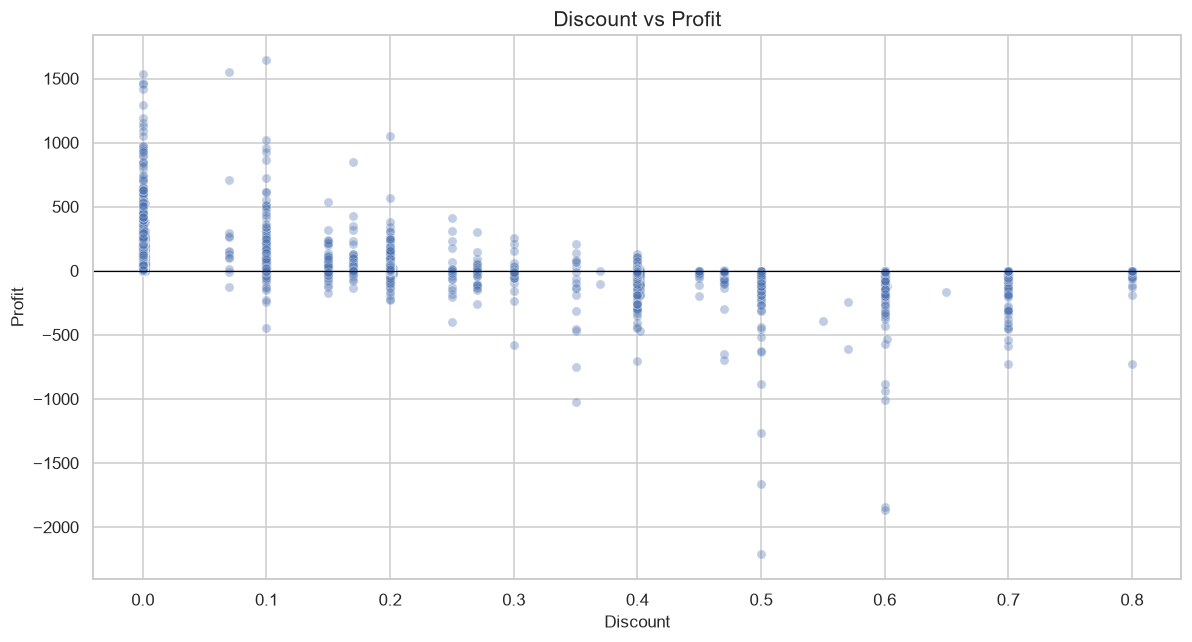

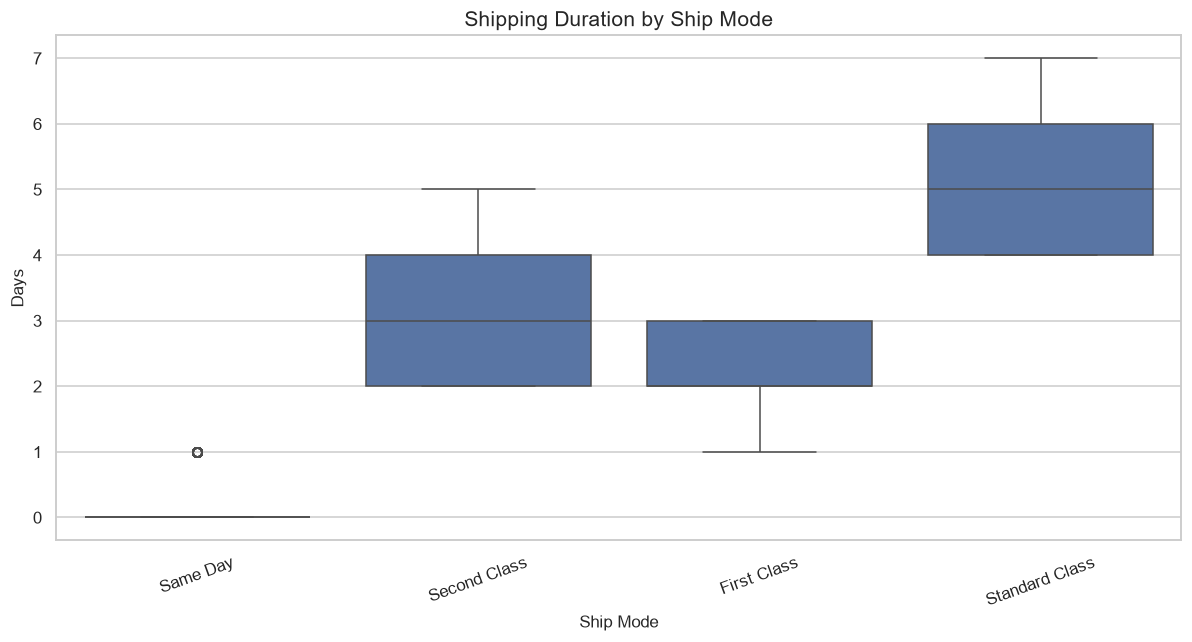

,Ship Mode,Sales,Profit,ShippingCost,Duration
3,Standard Class,7.578652e+06,890596.02120,19.971654,4.998018
2,Second Class,2.565672e+06,292583.52708,30.469666,3.230187
0,First Class,1.830976e+06,208104.67520,41.052970,2.181746
1,Same Day,6.672020e+05,76173.06780,42.937325,0.037394


,Order Priority,Count
0,Medium,29433
1,High,15501
2,Critical,3932
3,Low,2424


,Category,Discount
0,Furniture,0.168087
1,Office Supplies,0.137409
2,Technology,0.135342


,Discount,Sales,Profit,ProfitMargin
0,"(-0.001, 0.1]",8.955030e+06,2.108885e+06,25.189707
1,"(0.1, 0.2]",1.757261e+06,1.732548e+05,13.744969
2,"(0.2, 0.3]",3.825547e+05,-2.115561e+04,-3.851093
3,"(0.3, 0.4]",7.013431e+05,-1.661154e+05,-24.595408
4,"(0.4, 0.5]",4.746883e+05,-2.148294e+05,-45.006422
5,"(0.5, 0.6]",1.990353e+05,-1.734189e+05,-86.624144
6,"(0.6, 0.7]",1.513292e+05,-1.974779e+05,-133.214181
7,"(0.7, 0.8]",2.046333e+04,-3.861623e+04,-186.538558
8,"(0.8, 0.9]",7.968420e+02,-3.068658e+03,-410.016154


In [12]:

ship_mode_summary = sales_clean.groupby("Ship Mode", as_index=False).agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    ShippingCost=("Shipping Cost","mean"), Duration=("Shipping Duration","mean")
).sort_values("Sales", ascending=False)
priority_summary = sales_clean["Order Priority"].value_counts(dropna=False).rename_axis("Order Priority").reset_index(name="Count")
discount_category = sales_clean.groupby("Category", as_index=False)["Discount"].mean().sort_values("Discount", ascending=False)

discount_profit = sales_clean.groupby(pd.cut(sales_clean["Discount"], bins=np.arange(0, 1.01, 0.1), include_lowest=True),
                                      observed=True).agg(Sales=("Sales","sum"), Profit=("Profit","sum"),
                                                         ProfitMargin=("Profit Margin","mean")).reset_index()

fig, ax = plt.subplots()
sns.barplot(data=ship_mode_summary, x="Ship Mode", y="Profit", ax=ax, color="#0f766e")
ax.set(title="Profit by Ship Mode", ylabel="Profit")
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "ship_mode_profit.png")
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=sales_clean.sample(min(5000, len(sales_clean)), random_state=42),
                x="Discount", y="Profit", alpha=0.35, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Discount vs Profit", xlabel="Discount", ylabel="Profit")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "discount_vs_profit.png")
plt.show()

fig, ax = plt.subplots()
sns.boxplot(data=sales_clean, x="Ship Mode", y="Shipping Duration", ax=ax)
ax.set(title="Shipping Duration by Ship Mode", xlabel="Ship Mode", ylabel="Days")
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "shipping_duration.png")
plt.show()

display(ship_mode_summary)
display(priority_summary)
display(discount_category)
display(discount_profit)


The relationship plot is descriptive: it shows association, not causation. A discount policy could coincide with lower profit for several reasons, so further controlled or cost-based review is needed.

## Correlation and Statistical Analysis

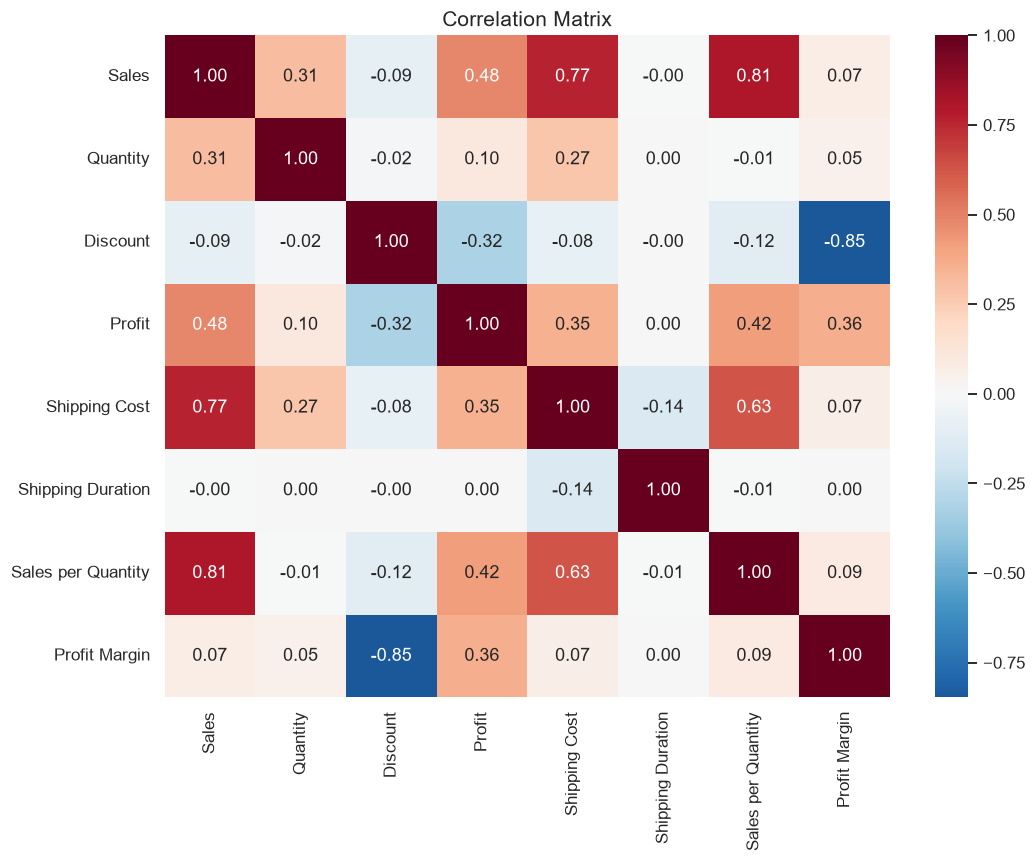

Sales: 5,655 observations outside 1.5 x IQR
Profit: 9,755 observations outside 1.5 x IQR
Shipping Cost: 5,909 observations outside 1.5 x IQR
Discount: 4,172 observations outside 1.5 x IQR


In [13]:

numeric_for_corr = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost",
                    "Shipping Duration", "Sales per Quantity", "Profit Margin"]
corr = sales_clean[numeric_for_corr].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title="Correlation Matrix")
fig.tight_layout()
fig.savefig(project_root / "Sales-Data-Analysis" / "outputs" / "charts" / "correlation_heatmap.png")
plt.show()

for column in ["Sales", "Profit", "Shipping Cost", "Discount"]:
    q1 = sales_clean[column].quantile(0.25)
    q3 = sales_clean[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = sales_clean[(sales_clean[column] < lower) | (sales_clean[column] > upper)]
    print(f"{column}: {len(outliers):,} observations outside 1.5 x IQR")


Correlation results summarize linear association for numerical fields. Outliers are not automatically errors; in sales data, they can represent large orders or unusual transactions.

## Save Cleaned and Summary Data

In [14]:

output_dir = project_root / "Sales-Data-Analysis" / "outputs"
chart_dir = output_dir / "charts"
output_dir.mkdir(parents=True, exist_ok=True)
chart_dir.mkdir(parents=True, exist_ok=True)

sales_clean.to_csv(output_dir / "cleaned_sales_data.csv", index=False)
year_sales.to_csv(output_dir / "year_wise_sales.csv", index=False)
quarter_sales.to_csv(output_dir / "quarter_sales.csv", index=False)
top_products_sales.to_csv(output_dir / "top_10_products_by_sales.csv", index=False)
top_products_profit.to_csv(output_dir / "top_10_products_by_profit.csv", index=False)
segment_summary.to_csv(output_dir / "segment_summary.csv", index=False)
region_sales.to_csv(output_dir / "region_sales.csv", index=False)
ship_mode_summary.to_csv(output_dir / "ship_mode_summary.csv", index=False)
print("Saved cleaned and summary data to:", output_dir)


Saved cleaned and summary data to: C:\Users\gp298\Desktop\Afame-Technologies\Sales-Data-Analysis\outputs


## Business Insights

In [15]:

best_year = year_sales.loc[year_sales["Sales"].idxmax()]
low_year = year_sales.loc[year_sales["Sales"].idxmin()]
top_product = top_products_sales.iloc[0]
top_profit_product = top_products_profit.iloc[0]
worst_subcategory = subcategory_profit.iloc[0]
top_segment = segment_summary.loc[segment_summary["Sales"].idxmax()]
top_region = region_sales.iloc[0]
top_country = country_sales.iloc[0]
top_ship = ship_mode_summary.iloc[0]
top_customer = top_customers_sales.iloc[0]

insights = [
    ("Strongest sales year", f"{best_year['Order Year']}: ${best_year['Sales']:,.2f}",
     "This period produced the largest recorded annual sales.", "Review the activities and conditions behind this year and apply suitable strategies to comparable periods."),
    ("Lowest annual sales", f"{low_year['Order Year']}: ${low_year['Sales']:,.2f}",
     "This period forms the baseline for improvement.", "Investigate campaigns, inventory, and market coverage that changed in this period."),
    ("Top product by sales", f"{top_product['Product Name']}: ${top_product['Sales']:,.2f}",
     "This product is the largest sales contributor.", "Protect availability and prioritize targeted promotions for this product."),
    ("Top product by profit", f"{top_profit_product['Product Name']}: ${top_profit_product['Profit']:,.2f}",
     "Revenue leadership and profit leadership are separate positions.", "Bundle or cross-sell profitable products with high-volume items."),
    ("Weakest sub-category", f"{worst_subcategory['Sub-Category']}: ${worst_subcategory['Profit']:,.2f}",
     "This sub-category recorded the lowest profit in the comparison.", "Review its pricing, discount levels, logistics costs, and product mix."),
    ("Leading customer segment", f"{top_segment['Segment']}: ${top_segment['Sales']:,.2f} sales",
     "This segment generated the largest segment revenue.", "Tailor retention and repeat-purchase offers to this segment."),
    ("Leading region", f"{top_region['Region']}: ${top_region['Sales']:,.2f}",
     "This region is an important revenue source.", "Investigate its strongest local categories and replicate useful execution patterns elsewhere."),
    ("Leading country", f"{top_country['Country']}: ${top_country['Sales']:,.2f}",
     "Country performance is concentrated.", "Maintain service levels in the leading market while monitoring underdeveloped markets."),
    ("Highest-volume ship mode", f"{top_ship['Ship Mode']}: ${top_ship['Sales']:,.2f} sales",
     "This mode is associated with a substantial sales share.", "Compare its cost and delivery duration before changing the customer policy."),
    ("Top customer", f"{top_customer['Customer Name']}: ${top_customer['Sales']:,.2f}",
     "This customer contributes the largest measured sales amount.", "Review account health and account-specific retention actions."),
]
display(pd.DataFrame(insights, columns=["Finding","Supporting value","Interpretation","Recommendation"]))


,Finding,Supporting value,Interpretation,Recommendation
0,Strongest sales year,"2014.0: $4,299,865.87",This period produced the largest recorded annu...,Review the activities and conditions behind th...
1,Lowest annual sales,"2011.0: $2,259,450.90",This period forms the baseline for improvement.,"Investigate campaigns, inventory, and market c..."
2,Top product by sales,"Apple Smart Phone, Full Size: $86,935.78",This product is the largest sales contributor.,Protect availability and prioritize targeted p...
3,Top product by profit,"Canon imageCLASS 2200 Advanced Copier: $25,199.93",Revenue leadership and profit leadership are s...,Bundle or cross-sell profitable products with ...
4,Weakest sub-category,"Tables: $-64,083.39",This sub-category recorded the lowest profit i...,"Review its pricing, discount levels, logistics..."
5,Leading customer segment,"Consumer: $6,507,949.42 sales",This segment generated the largest segment rev...,Tailor retention and repeat-purchase offers to...
6,Leading region,"Central: $2,822,302.52",This region is an important revenue source.,Investigate its strongest local categories and...
7,Leading country,"United States: $2,297,200.86",Country performance is concentrated.,Maintain service levels in the leading market ...
8,Highest-volume ship mode,"Standard Class: $7,578,652.11 sales",This mode is associated with a substantial sal...,Compare its cost and delivery duration before ...
9,Top customer,"Tom Ashbrook: $40,488.07",This customer contributes the largest measured...,Review account health and account-specific ret...



## Business Recommendations

1. **Product strategy:** Prioritize profitable products and review the discount and cost structure of high-sales, low-profit products.
2. **Pricing and discounts:** Test narrower discounts for low-margin categories instead of using uniform promotions.
3. **Regional strategy:** Support high-performing regions and investigate underperforming states before expanding inventory.
4. **Customer segment strategy:** Combine segment-level revenue information with retention analysis before making claims about loyalty.
5. **Shipping optimization:** Compare ship mode profit, cost, and duration together rather than optimizing for sales alone.
6. **Profit improvement:** Start with sub-categories that have negative profit and confirm whether shipping or discounting drives the loss.

## Final Conclusion
This analysis examined the real `Orders` sheet, cleaned and preserved the data, created time and profitability features, and connected sales performance to products, customers, regions, shipping, and discounts. The results are descriptive: they identify opportunities and risks but do not prove causation. The final decision should combine these findings with margin, cost, and operational data.

### Limitations
- The analysis uses historical transaction observations.
- Country and region coverage may be uneven.
- Cost of goods sold is not a separate field in the dataset, so profit margin is based on reported profit.
- Correlation does not establish whether discounts cause lower profit.

### Future Scope
- Add return and people sheets where a valid join is available.
- Build customer retention and repeat-purchase measures.
- Add cost data for stronger gross-margin analysis.
- Create an optional dashboard using validated notebook outputs.

## Author and Project Information
**Student:** [Add your name]  
**Organization:** AFAME Technologies  
**LinkedIn:** [Add your LinkedIn URL]  
**GitHub:** [Add your GitHub URL]
